# MathTrans — Phase 1 Full Notebook

**Before running:** Runtime → Change runtime type → **T4 GPU**

| Section | What it does |
|---|---|
| 0 | Install & mount Drive |
| 1 | All imports & config |
| 2 | Helper functions — each one shows example output |
| 3 | Model & tokenizer — inspect vocab, LoRA layers |
| 4 | Data pipeline — inspect each stage |
| 5 | Training — auto-resumes from checkpoint |
| 6 | Checkpoint explorer — test any of 6 checkpoints vs base model |
| 7 | Full metrics plots — loss, chrF++, BLEU, LR, bar chart |
| 8 | arXiv / PDF translator interface |
| 9 | Phase 2 — 11 k cleaned data: full pre-training pipeline with adjusted hyperparameters |
| 10 | Phase 2 checkpoint explorer — curves, bar chart, Phase 1 vs Phase 2 comparison |

## Section 0 — Install & mount Drive

In [ ]:
# 0.1 Install
!pip install -q transformers==4.40.2 peft==0.10.0 datasets accelerate==0.30.1 evaluate sacrebleu sentencepiece pymupdf4llm matplotlib requests beautifulsoup4
print("✓ packages installed")

✓ packages installed


In [ ]:
# 0.2 Mount Drive & set paths
from google.colab import drive
drive.mount('/content/drive')
import os, torch

DRIVE_ROOT  = '/content/drive/MyDrive/mathtrans'
DATA_PATH   = f'{DRIVE_ROOT}/phase1.jsonl'
CKPT_DIR    = f'{DRIVE_ROOT}/checkpoints'
SEEN_PATH   = f'{DRIVE_ROOT}/seen_hashes.txt'
CURVES_PATH = f'{CKPT_DIR}/training_curves.json'
os.makedirs(CKPT_DIR, exist_ok=True)

print(f"GPU : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE — go to Runtime → Change runtime type'}")
if torch.cuda.is_available():
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
print(f"Data file exists: {os.path.exists(DATA_PATH)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU : Tesla T4
VRAM: 15.6 GB
Data file exists: True


## Section 1 — Imports & config

In [ ]:
# 1.1 All imports
import os, re, json, math, hashlib, logging, warnings
from pathlib import Path
from IPython.display import display, HTML

os.environ.setdefault('PYTORCH_ALLOC_CONF', 'expandable_segments:True')
warnings.filterwarnings('ignore')

import torch, numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from datasets import Dataset, DatasetDict
from transformers import (
    NllbTokenizerFast, AutoModelForSeq2SeqLM,
    Seq2SeqTrainer, Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq, EarlyStoppingCallback, TrainerCallback,
)
from peft import LoraConfig, TaskType, get_peft_model
import evaluate as hf_evaluate

device = 'cuda' if torch.cuda.is_available() else 'cpu'
logging.basicConfig(level=logging.INFO, format='%(asctime)s | %(levelname)s | %(message)s')
log = logging.getLogger(__name__)
print("✓ All imports OK  |  device:", device)

✓ All imports OK  |  device: cuda


In [ ]:
# 1.2 Config — edit values here, everything else reads from these dicts
MODEL_NAME = 'facebook/nllb-200-1.3B'
LANG_CODE  = {'en': 'eng_Latn', 'ar': 'arb_Arab'}

LORA_CONFIG = dict(
    r=16, lora_alpha=32,
    target_modules=['q_proj','k_proj','v_proj','out_proj'],
    lora_dropout=0.05, bias='none',
    task_type=TaskType.SEQ_2_SEQ_LM,
)

TRAIN_CONFIG = dict(
    max_source_length=256, max_target_length=256,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=16,    # effective batch = 64
    learning_rate=3e-4,
    lr_scheduler_type='cosine',
    warmup_ratio=0.06,
    num_train_epochs=3,
    weight_decay=0.01,
    label_smoothing_factor=0.0,       # must be 0.0 with PEFT
    val_split=0.05,
    logging_steps=50,
    eval_steps=200,
    save_steps=200,
    save_total_limit=5,
    eval_num_beams=1,                 # greedy eval = no OOM
    eval_generation_max_length=128,
    final_num_beams=4,
    final_generation_max_length=256,
    seed=42,
)

for k,v in TRAIN_CONFIG.items():
    print(f"  {k:<35} = {v}")

  max_source_length                   = 256
  max_target_length                   = 256
  per_device_train_batch_size         = 4
  per_device_eval_batch_size          = 4
  gradient_accumulation_steps         = 16
  learning_rate                       = 0.0003
  lr_scheduler_type                   = cosine
  warmup_ratio                        = 0.06
  num_train_epochs                    = 3
  weight_decay                        = 0.01
  label_smoothing_factor              = 0.0
  val_split                           = 0.05
  logging_steps                       = 50
  eval_steps                          = 200
  save_steps                          = 200
  save_total_limit                    = 5
  eval_num_beams                      = 1
  eval_generation_max_length          = 128
  final_num_beams                     = 4
  final_generation_max_length         = 256
  seed                                = 42






## Section 2 — Helper functions

Run each cell to define the function. The inspection block at the bottom of each cell shows real output.

In [ ]:
# 2.1 Sentence splitter  +  inspection
_SENT_SPLIT = re.compile(r'(?<=[.!?\u061F])\s+(?=[A-Z\u0600-\u06FF"])')
_ABBREV = re.compile(
    r'\b(Thm|Lem|Prop|Cor|Def|Eq|Fig|Sec|Ch|Vol|et al|e\.g|i\.e|vs|cf|resp|approx)\.\s',
    re.IGNORECASE,
)

def split_sentences(text):
    protected = _ABBREV.sub(lambda m: m.group().replace('. ', '\x00 '), text)
    parts = _SENT_SPLIT.split(protected)
    return [p.replace('\x00','.').strip() for p in parts if p.strip()]

def split_pair(src, tgt):
    direction, clean_src = '', src
    if src.startswith('<en2ar>'): direction, clean_src = '<en2ar>', src[7:].strip()
    elif src.startswith('<ar2en>'): direction, clean_src = '<ar2en>', src[7:].strip()
    src_sents = split_sentences(clean_src)
    tgt_sents = split_sentences(tgt)
    if len(src_sents)==len(tgt_sents) and len(src_sents)>1:
        pairs=[]
        for s,t in zip(src_sents,tgt_sents):
            if len(s)>=10 and len(t)>=10:
                tag=f'{direction} ' if direction else ''
                pairs.append((f'{tag}{s}',t))
        return pairs if pairs else [(src,tgt)]
    return [(src,tgt)]

# ── inspection ──
EXAMPLE_SRC = '<en2ar> Let f be a measurable function. We say f is integrable if the Lebesgue integral of |f| is finite. This condition is equivalent to f being in L^1.'
EXAMPLE_TGT = 'لتكن f دالة قابلة للقياس. نقول إن f قابلة للتكامل إذا كان تكامل لوبيغ لـ|f| منتهياً. هذا الشرط يعادل كون f في L^1.'
pairs = split_pair(EXAMPLE_SRC, EXAMPLE_TGT)
print(f"1 abstract → {len(pairs)} sentence pairs:")
for i,(s,t) in enumerate(pairs):
    print(f"  [{i}] EN: {s}")
    print(f"       AR: {t}")

1 abstract → 3 sentence pairs:
  [0] EN: <en2ar> Let f be a measurable function.
       AR: لتكن f دالة قابلة للقياس.
  [1] EN: <en2ar> We say f is integrable if the Lebesgue integral of |f| is finite.
       AR: نقول إن f قابلة للتكامل إذا كان تكامل لوبيغ لـ|f| منتهياً.
  [2] EN: <en2ar> This condition is equivalent to f being in L^1.
       AR: هذا الشرط يعادل كون f في L^1.


In [ ]:
# 2.2 Seen-hash tracking  +  inspection
def pair_hash(src):
    clean = re.sub(r'^<(en2ar|ar2en)>\s*','',src).lower()[:120]
    return hashlib.md5(clean.encode()).hexdigest()

def load_seen_hashes(path):
    p=Path(path)
    return set(p.read_text().splitlines()) if p.exists() else set()

def save_new_hashes(path, hashes):
    with open(path,'a',encoding='utf-8') as f:
        for h in hashes: f.write(h+'\n')
    print(f"  Saved {len(hashes)} hashes → {path}")

# ── inspection ──
h1=pair_hash('<en2ar> The function f is continuous.')
h2=pair_hash('<en2ar> The function f is continuous.')
h3=pair_hash('<ar2en> الدالة f مستمرة.')
print(f"Same sentence twice     : {h1==h2}  (identical hash = dedup works)")
print(f"Different sentence      : {h1!=h3}  (different hash = not deduped)")
print(f"Hash example            : {h1}")

Same sentence twice     : True  (identical hash = dedup works)
Different sentence      : True  (different hash = not deduped)
Hash example            : 73695a74ff7f8468d9bdbc62e7ecb2cc


In [ ]:
# 2.3 Data loading  +  inspection
def load_data(data_paths, seen_hashes, val_split=0.05, seed=42, retrain_all=False):
    records,new_hashes,dedup=[],[],set()
    n_seen=n_invalid=n_split=0
    for path in data_paths:
        with open(path,encoding='utf-8') as f:
            for line in f:
                line=line.strip()
                if not line: continue
                try: obj=json.loads(line)
                except: n_invalid+=1; continue
                src=obj.get('source','').strip()
                tgt=obj.get('target','').strip()
                if not src or not tgt or len(src)<10 or len(tgt)<10:
                    n_invalid+=1; continue
                h=pair_hash(src)
                if not retrain_all and h in seen_hashes: n_seen+=1; continue
                if h in dedup: continue
                dedup.add(h)
                pairs=split_pair(src,tgt)
                if len(pairs)>1: n_split+=1
                for s,t in pairs:
                    if len(s)>=10 and len(t)>=10 and s!=t:
                        records.append({'source':s,'target':t})
                new_hashes.append(h)
    print(f"  Sentence pairs loaded : {len(records)}")
    print(f"  Raw pairs             : {len(new_hashes)}")
    print(f"  Multi-sent expanded   : {n_split}")
    print(f"  Skipped seen          : {n_seen}  |  invalid: {n_invalid}")
    ds=Dataset.from_list(records)
    split=ds.train_test_split(test_size=val_split,seed=seed)
    return DatasetDict({'train':split['train'],'validation':split['test']}),new_hashes

# ── inspection ──
if os.path.exists(DATA_PATH):
    seen=load_seen_hashes(SEEN_PATH)
    print(f"Seen hashes: {len(seen)}")
    datasets,new_hashes=load_data([DATA_PATH],seen)
    src_lens=[len(r['source'].split()) for r in datasets['train']]
    tgt_lens=[len(r['target'].split()) for r in datasets['train']]
    en2ar=sum(1 for r in datasets['train'] if r['source'].startswith('<en2ar>'))
    ar2en=len(datasets['train'])-en2ar
    print(f"  Train/Val split : {len(datasets['train'])} / {len(datasets['validation'])}")
    print(f"  EN→AR / AR→EN   : {en2ar} / {ar2en}  ({100*en2ar/(en2ar+ar2en):.0f}% / {100*ar2en/(en2ar+ar2en):.0f}%)")
    print(f"  Src words avg/p95: {np.mean(src_lens):.1f} / {np.percentile(src_lens,95):.0f}")
    print(f"  Tgt words avg/p95: {np.mean(tgt_lens):.1f} / {np.percentile(tgt_lens,95):.0f}")
else:
    print(f"Data not found at {DATA_PATH} — upload your JSONL first")

Seen hashes: 0
  Sentence pairs loaded : 79670
  Raw pairs             : 78550
  Multi-sent expanded   : 581
  Skipped seen          : 0  |  invalid: 0
  Train/Val split : 75686 / 3984
  EN→AR / AR→EN   : 37871 / 37815  (50% / 50%)
  Src words avg/p95: 23.7 / 41
  Tgt words avg/p95: 22.7 / 40


In [ ]:
# 2.4 Tokenisation function  (instantiated after tokenizer loads in S3)
def make_tokenize_fn(tokenizer, max_src, max_tgt):
    def tokenize(batch):
        ii,am,lb=[],[],[]
        for src,tgt in zip(batch['source'],batch['target']):
            if src.startswith('<en2ar>'):
                tokenizer.src_lang=LANG_CODE['en']; tokenizer.tgt_lang=LANG_CODE['ar']
                clean=src[7:].strip()
            elif src.startswith('<ar2en>'):
                tokenizer.src_lang=LANG_CODE['ar']; tokenizer.tgt_lang=LANG_CODE['en']
                clean=src[7:].strip()
            else:
                has_ar=any('\u0600'<=c<='\u06FF' for c in src)
                tokenizer.src_lang=LANG_CODE['ar' if has_ar else 'en']
                tokenizer.tgt_lang=LANG_CODE['en' if has_ar else 'ar']
                clean=src
            enc=tokenizer(clean,max_length=max_src,truncation=True,padding=False)
            dec=tokenizer(text_target=tgt,max_length=max_tgt,truncation=True,padding=False)
            labels=[l if l!=tokenizer.pad_token_id else -100 for l in dec['input_ids']]
            ii.append(enc['input_ids']); am.append(enc['attention_mask']); lb.append(labels)
        return {'input_ids':ii,'attention_mask':am,'labels':lb}
    return tokenize
print("make_tokenize_fn defined — will be used after tokenizer loads")

make_tokenize_fn defined — will be used after tokenizer loads


In [ ]:
# 2.5 Metrics  +  inspection
def build_compute_metrics(tokenizer):
    chrf=hf_evaluate.load('chrf')
    bleu=hf_evaluate.load('sacrebleu')
    def compute_metrics(eval_preds):
        preds,labels=eval_preds
        if isinstance(preds,tuple): preds=preds[0]
        preds =np.where(preds !=-100,preds, tokenizer.pad_token_id)
        labels=np.where(labels!=-100,labels,tokenizer.pad_token_id)
        dp=[p.strip() for p in tokenizer.batch_decode(preds, skip_special_tokens=True)]
        dl=[l.strip() for l in tokenizer.batch_decode(labels,skip_special_tokens=True)]
        c=chrf.compute(predictions=dp,references=dl,word_order=2)
        b=bleu.compute(predictions=dp,references=[[l] for l in dl])
        return {'chrf':round(c['score'],2),'bleu':round(b['score'],2)}
    return compute_metrics

# ── inspection: what do these numbers mean? ──
chrf_m=hf_evaluate.load('chrf')
bleu_m=hf_evaluate.load('sacrebleu')
ref  = 'يُعرَّف تكامل لوبيغ لدالة قابلة للقياس غير سالبة بوصفه الحد الأعلى لتكاملات الدوال البسيطة'
good = 'يُعرَّف تكامل لوبيغ لدالة قابلة للقياس غير سالبة بوصفه الحد الأعلى'
bad  = 'هذه الجملة خاطئة تماما ولا علاقة لها بالنص الأصلي'
for label,pred in [('Good (partial match)',good),('Bad (wrong content)',bad)]:
    c=chrf_m.compute(predictions=[pred],references=[ref],word_order=2)
    b=bleu_m.compute(predictions=[pred],references=[[ref]])
    print(f"{label}:")
    print(f"  chrF++ = {c['score']:.1f}   BLEU = {b['score']:.1f}")

Good (partial match):
  chrF++ = 77.4   BLEU = 76.1
Bad (wrong content):
  chrF++ = 8.5   BLEU = 0.0


In [ ]:
# 2.6 Callbacks & checkpoint utils  +  inspection
class ClearCacheBeforeEval(TrainerCallback):
    def on_evaluate(self,args,state,control,**kw):
        if torch.cuda.is_available(): torch.cuda.empty_cache()

class SaveCurvesCallback(TrainerCallback):
    def __init__(self,path): self.path=path
    def on_evaluate(self,args,state,control,**kw):
        with open(self.path,'w') as f: json.dump(state.log_history,f,indent=2)

def find_checkpoints(output_dir):
    d=Path(output_dir)
    if not d.exists(): return []
    ckpts=sorted(d.glob('checkpoint-*'),key=lambda p:int(p.name.split('-')[-1]))
    return ckpts

def find_latest_checkpoint(output_dir):
    ckpts=find_checkpoints(output_dir)
    if not ckpts: return None,0
    latest=ckpts[-1]
    return str(latest),int(latest.name.split('-')[-1])

# ── inspection: list checkpoints ──
ckpts=find_checkpoints(CKPT_DIR)
if ckpts:
    print(f"Found {len(ckpts)} checkpoint(s):")
    for c in ckpts:
        size_mb=sum(f.stat().st_size for f in c.iterdir() if f.is_file())/1e6
        print(f"  {c.name:<25}  {size_mb:.0f} MB")
else:
    print("No checkpoints yet — they appear here after training starts (every 200 steps)")

Found 8 checkpoint(s):
  checkpoint-600             136 MB
  checkpoint-1000            136 MB
  checkpoint-2000            136 MB
  checkpoint-2600            136 MB
  checkpoint-2800            136 MB
  checkpoint-3000            136 MB
  checkpoint-3200            136 MB
  checkpoint-3400            136 MB


## Section 3 — Model & tokenizer setup

In [ ]:
# 3.1 Load tokenizer
print(f"Loading tokenizer: {MODEL_NAME}")
tokenizer=NllbTokenizerFast.from_pretrained(MODEL_NAME)
n_added=tokenizer.add_special_tokens({'additional_special_tokens':['<en2ar>','<ar2en>']})
print(f"Vocab size : {len(tokenizer)}")
print(f"Tokens added: {n_added}  (<en2ar>, <ar2en>)")

# ── inspection: see how NLLB tokenises a math sentence ──
tokenizer.src_lang='eng_Latn'
tok_out=tokenizer('The Lebesgue integral converges almost everywhere.',return_tensors='pt')
tokens=tokenizer.convert_ids_to_tokens(tok_out['input_ids'][0].tolist())
print(f"\nExample tokenisation:")
print(f"  Tokens : {tokens}")
print(f"  Count  : {tok_out['input_ids'].shape[1]} tokens  (direction token adds 1)")

Loading tokenizer: facebook/nllb-200-1.3B
Vocab size : 256206
Tokens added: 2  (<en2ar>, <ar2en>)

Example tokenisation:
  Tokens : ['eng_Latn', '▁The', '▁Leb', 'es', 'gue', '▁integral', '▁conver', 'ges', '▁almost', '▁everywhere', '.', '</s>']
  Count  : 12 tokens  (direction token adds 1)


In [ ]:
# 3.2 Load model & apply LoRA (downloads ~2.6 GB on first run)
print(f"Loading {MODEL_NAME} ...")
model=AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16 if device=='cuda' else torch.float32,
)
model.resize_token_embeddings(len(tokenizer))

model=get_peft_model(model,LoraConfig(**LORA_CONFIG))
for param in model.parameters():
        if param.requires_grad:
            param.data = param.data.to(torch.float32)
model.enable_input_require_grads()       # FIX 2: gradient flow
model.config.use_cache=False             # FIX 3: KV cache conflict
if hasattr(model.base_model,'prepare_decoder_input_ids_from_labels'):  # FIX 4
    model.prepare_decoder_input_ids_from_labels=model.base_model.prepare_decoder_input_ids_from_labels
model.print_trainable_parameters()

# ── inspection: parameter breakdown ──
total  =sum(p.numel() for p in model.parameters())
trained=sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"  Total     : {total/1e6:.1f}M")
print(f"  Trainable : {trained/1e6:.2f}M  ({100*trained/total:.3f}%  — these are the LoRA adapters)")
print(f"  Frozen    : {(total-trained)/1e6:.1f}M  — base NLLB weights, unchanged")
print(f"\nLoRA layers (first 6):")
for n,p in list(model.named_parameters())[:6]:
    if p.requires_grad: print(f"  {n}")

Loading facebook/nllb-200-1.3B ...
trainable params: 9,437,184 || all params: 1,380,075,520 || trainable%: 0.6838164914337441
  Total     : 1380.1M
  Trainable : 9.44M  (0.684%  — these are the LoRA adapters)
  Frozen    : 1370.6M  — base NLLB weights, unchanged

LoRA layers (first 6):
  base_model.model.model.encoder.layers.0.self_attn.k_proj.lora_A.default.weight
  base_model.model.model.encoder.layers.0.self_attn.k_proj.lora_B.default.weight


## Section 4 — Data pipeline inspection

> Ajouter une citation



In [ ]:
# 4.1 Inspect raw data
if not os.path.exists(DATA_PATH):
    print(f"ERROR: {DATA_PATH} not found")
else:
    print("First 3 training pairs after loading & splitting:")
    for i in range(min(3,len(datasets['train']))):
        r=datasets['train'][i]
        print(f"  [{i}] src: {r['source']}")
        print(f"       tgt: {r['target']}")
        print()

First 3 training pairs after loading & splitting:
  [0] src: <en2ar> Moreover, it is established that any other radial periodic solution must be subharmonic with period $nT_1$ for some integer $n > 1$, with at most one such solution for each $n$.
       tgt: علاوة على ذلك، يتم إثبات أن أي حل دوري شعاعي آخر يجب أن يكون تحت هارموني مع فترة $nT_1$ لبعض الأعداد الصحيحة $n > 1$، مع وجود حل واحد فقط من هذا النوع لكل $n$.

  [1] src: <en2ar> In this paper we investigate the covering machinery of the Jensen-Steel core model $K$, under the hypothesis that there is no inner model with a Woodin cardinal.
       tgt: في هذه الورقة، نستكشف آلية التغطية لنموذج قلب جنسن-ستيل $K$، تحت فرضية عدم وجود نموذج داخلي يحتوي على عدد وودين.

  [2] src: <en2ar> In this paper we introduce a generalization of classical risk measures in which the risk is represented by a step function taking two values, corresponding to two endogenously determined market regimes.
       tgt: في هذه الورقة نقدم تعميماً لمقاييس المخ

In [ ]:
# 4.2 Tokenise dataset & inspect token lengths
print("Tokenising (~30s for 78K pairs) ...")
tokenized=datasets.map(
    make_tokenize_fn(tokenizer,TRAIN_CONFIG['max_source_length'],TRAIN_CONFIG['max_target_length']),
    batched=True,batch_size=500,
    remove_columns=['source','target'],
    desc='Tokenising',num_proc=1,
)
row=tokenized['train'][0]
print(f"\nTokenised row shape:")
print(f"  input_ids      : ({len(row['input_ids'])},)")
print(f"  attention_mask : ({len(row['attention_mask'])},)")
print(f"  labels         : ({len(row['labels'])},)   first 10: {row['labels'][:10]}")
print(f"  (-100 = padding token, ignored in loss)")
tok_lens=[len(r['input_ids']) for r in tokenized['train']]
trunc=sum(1 for l in tok_lens if l==TRAIN_CONFIG['max_source_length'])
print(f"\nToken length distribution:")
print(f"  avg={np.mean(tok_lens):.1f}  p95={np.percentile(tok_lens,95):.0f}  max={max(tok_lens)}")
print(f"  Truncated at 256: {trunc} ({100*trunc/len(tok_lens):.1f}%)  — ideally <2%")

Tokenising (~30s for 78K pairs) ...


Tokenising:   0%|          | 0/75686 [00:00<?, ? examples/s]

Tokenising:   0%|          | 0/3984 [00:00<?, ? examples/s]


Tokenised row shape:
  input_ids      : (52,)
  attention_mask : (52,)
  labels         : (63,)   first 10: [256011, 22211, 89200, 6481, 11059, 248238, 99039, 972, 248779, 36572]
  (-100 = padding token, ignored in loss)

Token length distribution:
  avg=49.1  p95=90  max=256
  Truncated at 256: 51 (0.1%)  — ideally <2%


## Section 5 — Training

**Re-run this single cell after any Colab disconnect** — resumes from latest checkpoint automatically.

In [ ]:
import torch
import numpy._core.multiarray

# Whitelist all the NumPy objects PyTorch 2.6 is afraid of
torch.serialization.add_safe_globals([
    numpy._core.multiarray._reconstruct,
    numpy.ndarray,
    numpy.dtype,
    numpy.dtypes.UInt32DType  # <-- The new one!
])
# 5.1 Full training loop  —  re-run after any disconnect
cfg=TRAIN_CONFIG
eff_batch=cfg['per_device_train_batch_size']*cfg['gradient_accumulation_steps']
n_train=len(tokenized['train'])
steps_epoch=math.ceil(n_train/eff_batch)
total_steps=steps_epoch*cfg['num_train_epochs']
last_ckpt,steps_done=find_latest_checkpoint(CKPT_DIR)

print(f"Checkpoint     : {last_ckpt or 'none — fresh start'}")
print(f"Steps done     : {steps_done} / {total_steps}")
print(f"Steps/epoch    : {steps_epoch}")
print(f"Est. remaining : ~{max(0,total_steps-steps_done)*3.5/3600:.1f} h on T4")

training_args=Seq2SeqTrainingArguments(
    output_dir=CKPT_DIR,
    per_device_train_batch_size=cfg['per_device_train_batch_size'],
    per_device_eval_batch_size=cfg['per_device_eval_batch_size'],
    gradient_accumulation_steps=cfg['gradient_accumulation_steps'],
    learning_rate=cfg['learning_rate'],
    lr_scheduler_type=cfg['lr_scheduler_type'],
    warmup_ratio=cfg['warmup_ratio'],
    num_train_epochs=cfg['num_train_epochs'],
    weight_decay=cfg['weight_decay'],
    label_smoothing_factor=cfg['label_smoothing_factor'],
    fp16=(device=='cuda'),
    save_strategy='steps',save_steps=cfg['save_steps'],save_total_limit=cfg['save_total_limit'],
    evaluation_strategy='steps',eval_steps=cfg['eval_steps'],
    load_best_model_at_end=True,metric_for_best_model='chrf',greater_is_better=True,
    predict_with_generate=True,
    generation_num_beams=cfg['eval_num_beams'],
    generation_max_length=cfg['eval_generation_max_length'],
    gradient_checkpointing=False,
    dataloader_pin_memory=(device=='cuda'),
    logging_steps=cfg['logging_steps'],
    report_to='none',seed=cfg['seed'],
)
trainer=Seq2SeqTrainer(
    model=model,args=training_args,
    train_dataset=tokenized['train'],eval_dataset=tokenized['validation'],
    tokenizer=tokenizer,
    data_collator=DataCollatorForSeq2Seq(
        tokenizer,model=model,padding='longest',
        pad_to_multiple_of=8,label_pad_token_id=-100,
    ),
    compute_metrics=build_compute_metrics(tokenizer),
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=2),
        ClearCacheBeforeEval(),
        SaveCurvesCallback(CURVES_PATH),
    ],
)

trainer.train(resume_from_checkpoint=last_ckpt)

save_new_hashes(SEEN_PATH,new_hashes)
with open(CURVES_PATH,'w') as f: json.dump(trainer.state.log_history,f,indent=2)
print(f"Curves saved to {CURVES_PATH}")

model.config.use_cache=True
final_dir=Path(CKPT_DIR)/'final'
print(f"Merging LoRA → {final_dir}")
model.merge_and_unload().save_pretrained(str(final_dir))
tokenizer.save_pretrained(str(final_dir))
model = model.half() # <--- THIS FIXES THE CRASH

torch.cuda.empty_cache()
m=trainer.evaluate(max_length=cfg['final_generation_max_length'],num_beams=cfg['final_num_beams'])
print(f"Final chrF++ : {m.get('eval_chrf','?')}")
print(f"Final BLEU   : {m.get('eval_bleu','?')}")

Checkpoint     : /content/drive/MyDrive/mathtrans/checkpoints/checkpoint-3400
Steps done     : 3400 / 3549
Steps/epoch    : 1183
Est. remaining : ~0.1 h on T4


Step,Training Loss,Validation Loss


## Section 6 — Checkpoint explorer




Load any checkpoint, test on a train example and an eval example, compare with base model.

In [ ]:
# 6.1 Translation helper & test sentences
def translate(text,tok,mdl,src='en',tgt='ar',beams=4,max_len=256):
    tok.src_lang=LANG_CODE[src]; tok.tgt_lang=LANG_CODE[tgt]
    inputs=tok(text,return_tensors='pt',max_length=max_len,truncation=True).to(device)
    forced_bos = tok.convert_tokens_to_ids(LANG_CODE[tgt])
    with torch.no_grad():
        out=mdl.generate(**inputs,forced_bos_token_id=forced_bos,
                         num_beams=beams,max_length=max_len,early_stopping=True)
    return tok.decode(out[0],skip_special_tokens=True).strip()

# Two test sentences — one in-distribution (train-like), one harder (eval-like)
TEST_TRAIN = 'The Lebesgue integral of a non-negative measurable function is the supremum of integrals of simple functions bounded above by it.'
TEST_EVAL  = 'Let 𝑓 f be a continuously differentiable function on a compact interval [ 𝑎 , 𝑏 ] [a,b]; prove that if 𝑓 ′ ( 𝑥 ) > 0 f ′ (x)>0 for all 𝑥 ∈ ( 𝑎 , 𝑏 ) x∈(a,b), then 𝑓 f is strictly increasing and attains its maximum at 𝑥 = 𝑏 x=b.'
REF_TRAIN  = 'تكامل لوبيغ لدالة قابلة للقياس غير سالبة هو الحد الأعلى لتكاملات الدوال البسيطة المحدودة من الأعلى بها.'
REF_EVAL   = 'لتكن 𝑓 f دالة قابلة للاشتقاق بشكل مستمر على مجال مغلق ومحدود [ 𝑎 , 𝑏 ] [a,b]، برهن أنه إذا كان 𝑓 ′ ( 𝑥 ) > 0 f ′ (x)>0 لكل 𝑥 ∈ ( 𝑎 , 𝑏 ) x∈(a,b)، فإن 𝑓 f دالة متزايدة تمامًا وتبلغ قيمتها العظمى عند 𝑥 = 𝑏 x=b.'

chrf_m=hf_evaluate.load('chrf')
print("Test sentences defined.")

Test sentences defined.


In [ ]:
# 6.2 Base model baseline (run once)
print("Loading base NLLB (no fine-tuning) ...")
base_tok=NllbTokenizerFast.from_pretrained(MODEL_NAME)
base_mdl=AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME,torch_dtype=torch.float16 if device=='cuda' else torch.float32
).to(device)
base_mdl.eval()

base_t=translate(TEST_TRAIN,base_tok,base_mdl)
base_e=translate(TEST_EVAL, base_tok,base_mdl)
base_chrf_t=chrf_m.compute(predictions=[base_t],references=[REF_TRAIN],word_order=2)['score']
base_chrf_e=chrf_m.compute(predictions=[base_e],references=[REF_EVAL], word_order=2)['score']

print(f"\n── BASE MODEL ──")
print(f"Train ex → {base_t}")
print(f"Eval  ex → {base_e}")
print(f"chrF++ train={base_chrf_t:.1f}  eval={base_chrf_e:.1f}")

Loading base NLLB (no fine-tuning) ...

── BASE MODEL ──
Train ex → تكامل ليبسغي من وظيفة قابلة للقياس غير سلبية هو أعلى تكاملات الوظائف البسيطة المحدودة أعلاه بها.
Eval  ex → فليكن f f دالة قابلة للتفاضل باستمرار على فترة ضيقة [ a, b ] [ a, b ] ؛ أثبت أنه إذا كان f ′ (x ) > 0 f ′ (x) > 0 لجميع x ∈ (a, b) x∈(a,b) ، ثم f f يزداد بشكل صارم ويحقق أقصى حد له عند x = b x = b.
chrF++ train=49.3  eval=33.1


In [ ]:
# 6.1 & 6.2 Random Sampling & Base Model Baseline
import random
from tqdm.auto import tqdm
import evaluate as hf_evaluate

print("Loading scoring metrics and sampling 100 random examples...")
chrf_m = hf_evaluate.load('chrf')
bleu_m = hf_evaluate.load('sacrebleu')

# Sample 100 random examples from the dataset we loaded in Section 2
NUM_SAMPLES = 100
random.seed(42) # Ensures we pick the exact same 100 examples every time we run it
train_samples = [datasets['train'][i] for i in random.sample(range(len(datasets['train'])), NUM_SAMPLES)]
eval_samples = [datasets['validation'][i] for i in random.sample(range(len(datasets['validation'])), NUM_SAMPLES)]

# Upgraded Translation Helper
def translate(text, tok, mdl, src='en', tgt='ar', beams=4, max_len=256):
    tok.src_lang = LANG_CODE[src]
    tok.tgt_lang = LANG_CODE[tgt]
    inputs = tok(text, return_tensors='pt', max_length=max_len, truncation=True).to(device)
    forced_bos = tok.convert_tokens_to_ids(LANG_CODE[tgt])
    with torch.no_grad():
        out = mdl.generate(**inputs, forced_bos_token_id=forced_bos,
                         num_beams=beams, max_length=max_len, early_stopping=True)
    return tok.decode(out[0], skip_special_tokens=True).strip()

# Automated Evaluator for 100 sentences
def evaluate_100_samples(samples, tok, mdl):
    preds, refs = [], []
    for row in tqdm(samples, desc="Translating 100 examples", leave=False):
        raw_src = row['source']

        # Figure out the direction and clean the <en2ar> tags so it doesn't confuse the model
        if raw_src.startswith('<en2ar>'):
            clean_src = raw_src.replace('<en2ar>', '').strip()
            s_lang, t_lang = 'en', 'ar'
        else:
            clean_src = raw_src.replace('<ar2en>', '').strip()
            s_lang, t_lang = 'ar', 'en'

        pred = translate(clean_src, tok, mdl, src=s_lang, tgt=t_lang)
        preds.append(pred)
        refs.append(row['target'])

    c = chrf_m.compute(predictions=preds, references=refs, word_order=2)['score']
    b = bleu_m.compute(predictions=preds, references=[[r] for r in refs])['score']
    return c, b

print("Loading base NLLB (no fine-tuning) ...")
base_tok = NllbTokenizerFast.from_pretrained(MODEL_NAME)
base_mdl = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float16).to(device)
base_mdl.eval()

print(f"\n── BASE MODEL (100-Example Average) ──")
base_train_chrf, base_train_bleu = evaluate_100_samples(train_samples, base_tok, base_mdl)
base_eval_chrf, base_eval_bleu = evaluate_100_samples(eval_samples, base_tok, base_mdl)

print(f"Train Set (100x) → chrF++: {base_train_chrf:.2f} | BLEU: {base_train_bleu:.2f}")
print(f"Eval Set  (100x) → chrF++: {base_eval_chrf:.2f} | BLEU: {base_eval_bleu:.2f}")

# Free up memory
del base_mdl
torch.cuda.empty_cache()

Loading scoring metrics and sampling 100 random examples...
Loading base NLLB (no fine-tuning) ...

── BASE MODEL (100-Example Average) ──


Translating 100 examples:   0%|          | 0/100 [00:00<?, ?it/s]

Translating 100 examples:   0%|          | 0/100 [00:00<?, ?it/s]

Train Set (100x) → chrF++: 64.00 | BLEU: 48.07
Eval Set  (100x) → chrF++: 63.74 | BLEU: 42.98


In [ ]:
# 6.3 Pick one checkpoint and compare
# ✏️  Change CKPT_INDEX to inspect a different checkpoint
# 0 = earliest   -1 = latest

from peft import PeftModel

ckpts=find_checkpoints(CKPT_DIR)
if not ckpts:
    print("No checkpoints yet. Run Section 5 first.")
else:
    print("Available checkpoints:")
    for i,c in enumerate(ckpts):
        print(f"  [{i}] {c.name}")

    CKPT_INDEX = -1   # ← change this

    sel=ckpts[CKPT_INDEX]
    print(f"\nLoading {sel.name} ...")
    ft_tok=NllbTokenizerFast.from_pretrained(str(sel))
    ft_base=AutoModelForSeq2SeqLM.from_pretrained(
        MODEL_NAME,torch_dtype=torch.float16 if device=='cuda' else torch.float32)
    ft_base.resize_token_embeddings(len(ft_tok))
    ft_mdl=PeftModel.from_pretrained(ft_base,str(sel)).to(device)
    ft_mdl.eval()

    ft_t=translate(TEST_TRAIN,ft_tok,ft_mdl)
    ft_e=translate(TEST_EVAL, ft_tok,ft_mdl)
    ft_chrf_t=chrf_m.compute(predictions=[ft_t],references=[REF_TRAIN],word_order=2)['score']
    ft_chrf_e=chrf_m.compute(predictions=[ft_e],references=[REF_EVAL], word_order=2)['score']

    print(f"\n{'='*55}")
    print(f"CHECKPOINT: {sel.name}")
    print(f"{'='*55}")
    print(f"\nTRAIN EXAMPLE")
    print(f"  Source     : {TEST_TRAIN[:90]}...")
    print(f"  Reference  : {REF_TRAIN[:90]}...")
    print(f"  Base       : {base_t[:90]}   [chrF++={base_chrf_t:.1f}]")
    print(f"  Fine-tuned : {ft_t[:90]}   [chrF++={ft_chrf_t:.1f}]")
    print(f"  Delta      : {ft_chrf_t-base_chrf_t:+.1f}")
    print(f"\nEVAL EXAMPLE")
    print(f"  Source     : {TEST_EVAL[:90]}...")
    print(f"  Reference  : {REF_EVAL[:90]}...")
    print(f"  Base       : {base_e[:90]}   [chrF++={base_chrf_e:.1f}]")
    print(f"  Fine-tuned : {ft_e[:90]}   [chrF++={ft_chrf_e:.1f}]")
    print(f"  Delta      : {ft_chrf_e-base_chrf_e:+.1f}")

    del ft_mdl,ft_base; torch.cuda.empty_cache()

Available checkpoints:
  [0] checkpoint-600
  [1] checkpoint-1000
  [2] checkpoint-2000
  [3] checkpoint-2600
  [4] checkpoint-2800
  [5] checkpoint-3000
  [6] checkpoint-3200
  [7] checkpoint-3400

Loading checkpoint-3400 ...


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.



CHECKPOINT: checkpoint-3400

TRAIN EXAMPLE
  Source     : The Lebesgue integral of a non-negative measurable function is the supremum of integrals o...
  Reference  : تكامل لوبيغ لدالة قابلة للقياس غير سالبة هو الحد الأعلى لتكاملات الدوال البسيطة المحدودة م...
  Base       : تكامل ليبسغي من وظيفة قابلة للقياس غير سلبية هو أعلى تكاملات الوظائف البسيطة المحدودة أعلا   [chrF++=49.3]
  Fine-tuned : تكامل ليبغ لدالة قابلة للقياس غير سالبة هو الحد الأعلى لتكاملات الدوال البسيطة المحدودة أع   [chrF++=79.5]
  Delta      : +30.1

EVAL EXAMPLE
  Source     : Let 𝑓 f be a continuously differentiable function on a compact interval [ 𝑎 , 𝑏 ] [a,b]; p...
  Reference  : لتكن 𝑓 f دالة قابلة للاشتقاق بشكل مستمر على مجال مغلق ومحدود [ 𝑎 , 𝑏 ] [a,b]، برهن أنه إذا...
  Base       : فليكن f f دالة قابلة للتفاضل باستمرار على فترة ضيقة [ a, b ] [ a, b ] ؛ أثبت أنه إذا كان f   [chrF++=33.1]
  Fine-tuned : لتكن f f دالة قابلة للاشتقاق باستمرار على فترة مضغوطة [ a, b ] [a,b]؛ أثبت أنه إذا كان f ′   [chrF++=41.

In [ ]:
# 6.4 Sweep ALL checkpoints AND Final Model
from peft import PeftModel

sweep_results = []
all_ckpts = find_checkpoints(CKPT_DIR)

# Add the 'final' model to our list to sweep
final_path = Path(CKPT_DIR) / 'final'
if final_path.exists():
    all_ckpts.append(final_path)

print(f"Sweeping {len(all_ckpts)} models on 100 Eval examples each...")

for ckpt in all_ckpts:
    ckpt_name = ckpt.name if hasattr(ckpt, 'name') else ckpt.parts[-1]
    print(f"\nLoading {ckpt_name}...")

    ft_tok = NllbTokenizerFast.from_pretrained(str(ckpt))

    if ckpt_name == 'final':
        # Load final as a pure standalone model
        ft_mdl = AutoModelForSeq2SeqLM.from_pretrained(str(ckpt), torch_dtype=torch.float16).to(device)
    else:
        # Load checkpoints as LoRA attachments
        ft_base = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float16).to(device)
        ft_base.resize_token_embeddings(len(ft_tok))
        ft_mdl = PeftModel.from_pretrained(ft_base, str(ckpt)).to(device)

    ft_mdl.eval()

    # Run the 100 examples
    c, b = evaluate_100_samples(eval_samples, ft_tok, ft_mdl)
    print(f"Result -> chrF++: {c:.2f} | BLEU: {b:.2f}")

    sweep_results.append({
        'name': ckpt_name.replace('checkpoint-', 'ckpt-'),
        'chrf': c,
        'bleu': b
    })

    # Clean up memory before the next model
    del ft_mdl
    if ckpt_name != 'final': del ft_base
    torch.cuda.empty_cache()

Sweeping 9 models on 100 Eval examples each...

Loading checkpoint-600...


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


Translating 100 examples:   0%|          | 0/100 [00:00<?, ?it/s]

Result -> chrF++: 69.74 | BLEU: 51.04

Loading checkpoint-1000...


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


Translating 100 examples:   0%|          | 0/100 [00:00<?, ?it/s]

... (18 outputs left out)

Result -> chrF++: 74.61 | BLEU: 56.90

Loading final...


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


Translating 100 examples:   0%|          | 0/100 [00:00<?, ?it/s]

Result -> chrF++: 74.49 | BLEU: 56.60


## Section 7 — Full metrics plots

In [ ]:
# 7.1 Load training curves
if not os.path.exists(CURVES_PATH):
    print(f"No curves at {CURVES_PATH}  — train first (Section 5)")
    history=[]
else:
    with open(CURVES_PATH) as f: history=json.load(f)
    print(f"Loaded {len(history)} log entries from {CURVES_PATH}")
    print(f"Keys in last entry: {list(history[-1].keys()) if history else 'empty'}")

Loaded 88 log entries from /content/drive/MyDrive/mathtrans/checkpoints/training_curves.json
Keys in last entry: ['train_runtime', 'train_samples_per_second', 'train_steps_per_second', 'total_flos', 'train_loss', 'epoch', 'step']


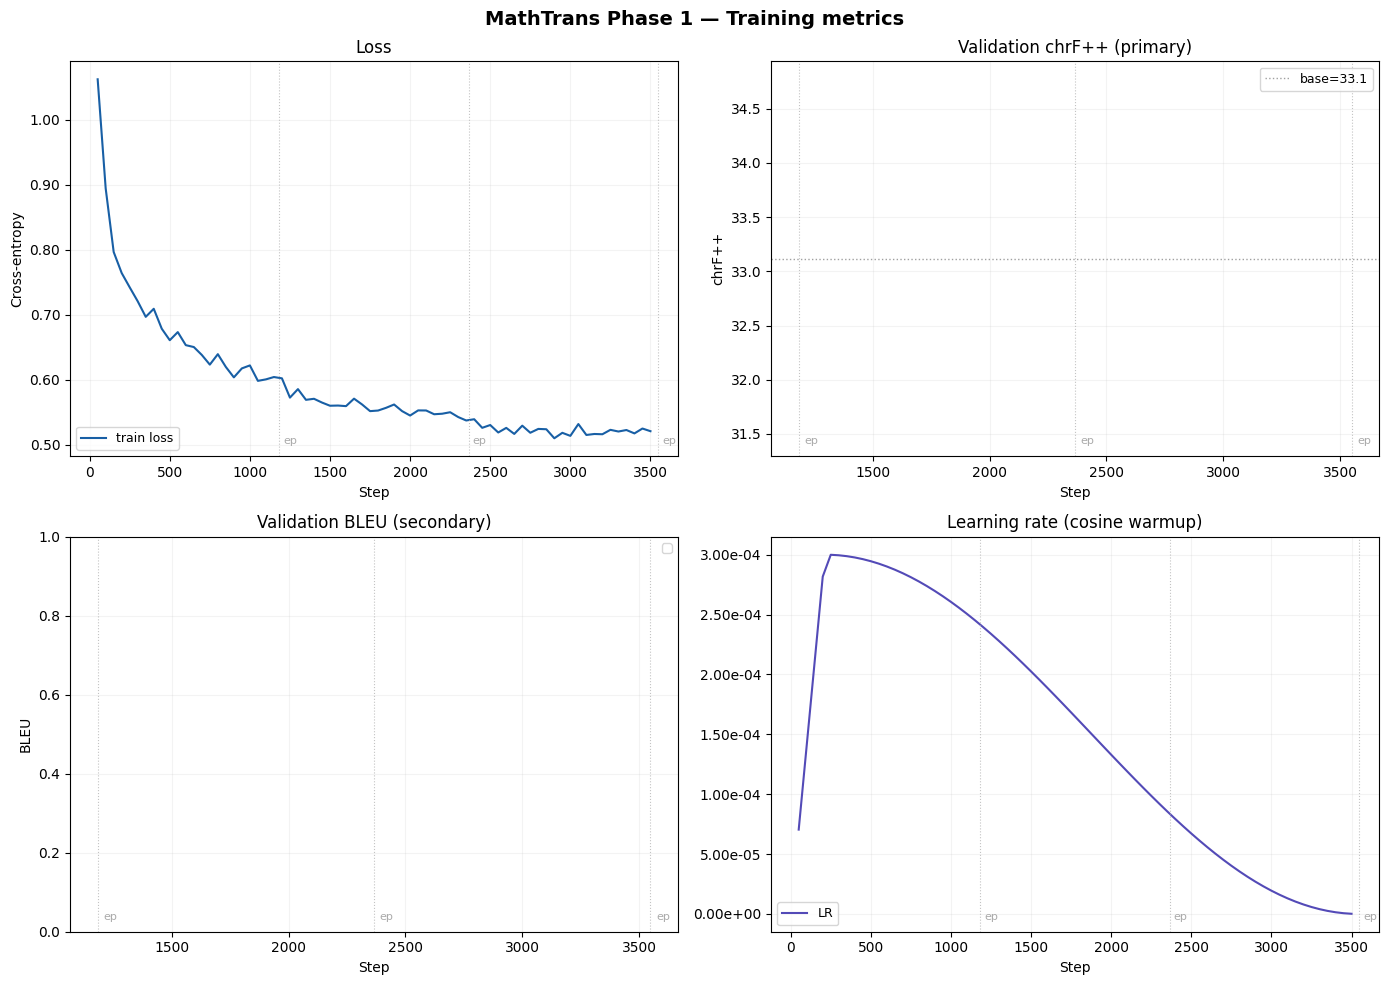

Saved → /content/drive/MyDrive/mathtrans/checkpoints/training_curves_full.png


In [ ]:
# 7.2 Full training curves — loss, chrF++, BLEU, learning rate
if not history:
    print("No history. Train at least one epoch then reload 7.1.")
else:
    train_logs=[h for h in history if 'loss' in h and 'eval_loss' not in h]
    eval_logs =[h for h in history if 'eval_chrf' in h]

    st=[h['step'] for h in train_logs]
    lt=[h['loss'] for h in train_logs]
    lr=[h.get('learning_rate',0) for h in train_logs]
    se=[h['step']       for h in eval_logs]
    ce=[h['eval_chrf']  for h in eval_logs]
    be=[h['eval_bleu']  for h in eval_logs]
    el=[h.get('eval_loss') for h in eval_logs]

    cfg=TRAIN_CONFIG
    spe=math.ceil(len(tokenized['train'])/(cfg['per_device_train_batch_size']*cfg['gradient_accumulation_steps']))
    epoch_marks=[spe*(i+1) for i in range(cfg['num_train_epochs'])]

    BLUE='#185FA5'; GREEN='#1D9E75'; ORANGE='#D85A30'; PURPLE='#534AB7'; TARGET='#BA7517'

    def epoch_lines(ax):
        ylim=ax.get_ylim()
        for es in epoch_marks:
            ax.axvline(x=es,color='#aaa',linestyle=':',linewidth=0.8,alpha=0.7)
            ax.text(es+max(st)/150,ylim[0]+(ylim[1]-ylim[0])*0.03,
                    f'ep',fontsize=8,color='#aaa')

    fig,axes=plt.subplots(2,2,figsize=(14,10))
    fig.suptitle('MathTrans Phase 1 — Training metrics',fontsize=14,fontweight='bold')

    # Loss
    ax=axes[0][0]
    if st: ax.plot(st,lt,color=BLUE,linewidth=1.5,label='train loss')
    valid_el=[(s,l) for s,l in zip(se,el) if l is not None]
    if valid_el: ax.plot([x[0] for x in valid_el],[x[1] for x in valid_el],
                         'o--',color=ORANGE,markersize=4,linewidth=1,label='eval loss')
    epoch_lines(ax)
    ax.set_title('Loss'); ax.set_xlabel('Step'); ax.set_ylabel('Cross-entropy')
    ax.legend(fontsize=9); ax.grid(alpha=0.15)
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))

    # chrF++
    ax=axes[0][1]
    if se:
        ax.plot(se,ce,color=GREEN,linewidth=2,marker='o',markersize=4,label='val chrF++')
        ax.axhline(y=45,color=TARGET,linestyle='--',linewidth=1.2,label='target 45',alpha=0.8)
        if ce:
            bi=ce.index(max(ce))
            ax.scatter([se[bi]],[ce[bi]],color=GREEN,s=80,zorder=5,
                       label=f'best={max(ce):.1f} @{se[bi]}')
    if 'base_chrf_e' in dir():
        ax.axhline(y=base_chrf_e,color='#888',linestyle=':',linewidth=1,
                   label=f'base={base_chrf_e:.1f}',alpha=0.8)
    epoch_lines(ax)
    ax.set_title('Validation chrF++ (primary)'); ax.set_xlabel('Step'); ax.set_ylabel('chrF++')
    ax.legend(fontsize=9); ax.grid(alpha=0.15)

    # BLEU
    ax=axes[1][0]
    if se:
        ax.plot(se,be,color=ORANGE,linewidth=2,marker='o',markersize=4,label='val BLEU')
        ax.axhline(y=25,color=TARGET,linestyle='--',linewidth=1.2,label='target 25',alpha=0.8)
    epoch_lines(ax)
    ax.set_title('Validation BLEU (secondary)'); ax.set_xlabel('Step'); ax.set_ylabel('BLEU')
    ax.legend(fontsize=9); ax.grid(alpha=0.15)

    # Learning rate
    ax=axes[1][1]
    if st: ax.plot(st,lr,color=PURPLE,linewidth=1.5,label='LR')
    epoch_lines(ax)
    ax.set_title('Learning rate (cosine warmup)'); ax.set_xlabel('Step')
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2e'))
    ax.legend(fontsize=9); ax.grid(alpha=0.15)

    plt.tight_layout()
    out=f'{CKPT_DIR}/training_curves_full.png'
    plt.savefig(out,dpi=150,bbox_inches='tight')
    plt.show()
    print(f"Saved → {out}")

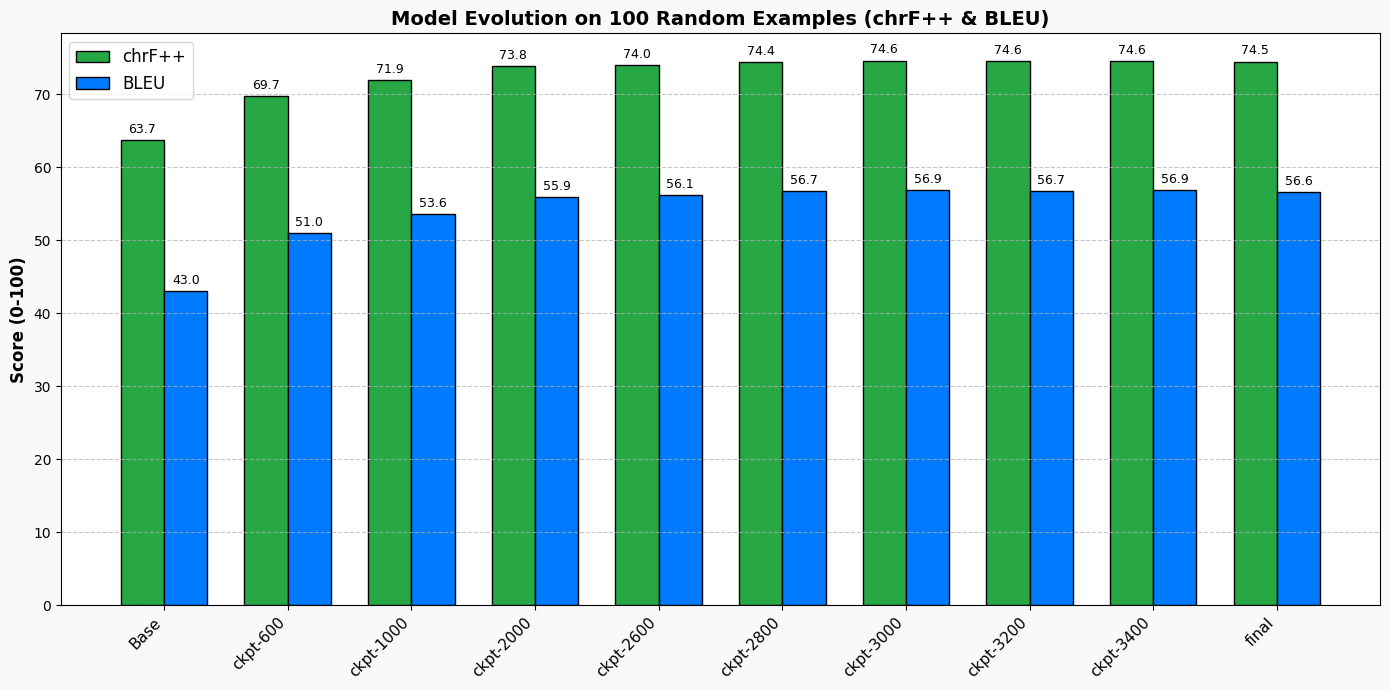

In [ ]:
# 7.3 Per-checkpoint chrF++ & BLEU bar chart
import matplotlib.pyplot as plt
import numpy as np

# Gather data
names = ['Base'] + [r['name'] for r in sweep_results]
chrf_scores = [base_eval_chrf] + [r['chrf'] for r in sweep_results]
bleu_scores = [base_eval_bleu] + [r['bleu'] for r in sweep_results]

x = np.arange(len(names))
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(14, 7), facecolor='#f8f9fa')
rects1 = ax.bar(x - width/2, chrf_scores, width, label='chrF++', color='#28a745', edgecolor='black')
rects2 = ax.bar(x + width/2, bleu_scores, width, label='BLEU', color='#007bff', edgecolor='black')

ax.set_ylabel('Score (0-100)', fontsize=12, fontweight='bold')
ax.set_title('Model Evolution on 100 Random Examples (chrF++ & BLEU)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=45, ha='right', fontsize=11)
ax.legend(fontsize=12)

ax.grid(axis='y', linestyle='--', alpha=0.7)

# Add text labels on top of the bars
for rects in [rects1, rects2]:
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
# 7.3 Per-checkpoint chrF++ & BLEU bar chart
import matplotlib.pyplot as plt
import numpy as np

# Gather data
names = ['Base'] + [r['name'] for r in sweep_results]
chrf_scores = [base_eval_chrf] + [r['chrf'] for r in sweep_results]
bleu_scores = [base_eval_bleu] + [r['bleu'] for r in sweep_results]

x = np.arange(len(names))
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(14, 7), facecolor='#f8f9fa')
rects1 = ax.bar(x - width/2, chrf_scores, width, label='chrF++', color='#28a745', edgecolor='black')
rects2 = ax.bar(x + width/2, bleu_scores, width, label='BLEU', color='#007bff', edgecolor='black')

ax.set_ylabel('Score (0-100)', fontsize=12, fontweight='bold')
ax.set_title('Model Evolution on 100 Random Examples (chrF++ & BLEU)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=45, ha='right', fontsize=11)
ax.legend(fontsize=12)

ax.grid(axis='y', linestyle='--', alpha=0.7)

# Add text labels on top of the bars
for rects in [rects1, rects2]:
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

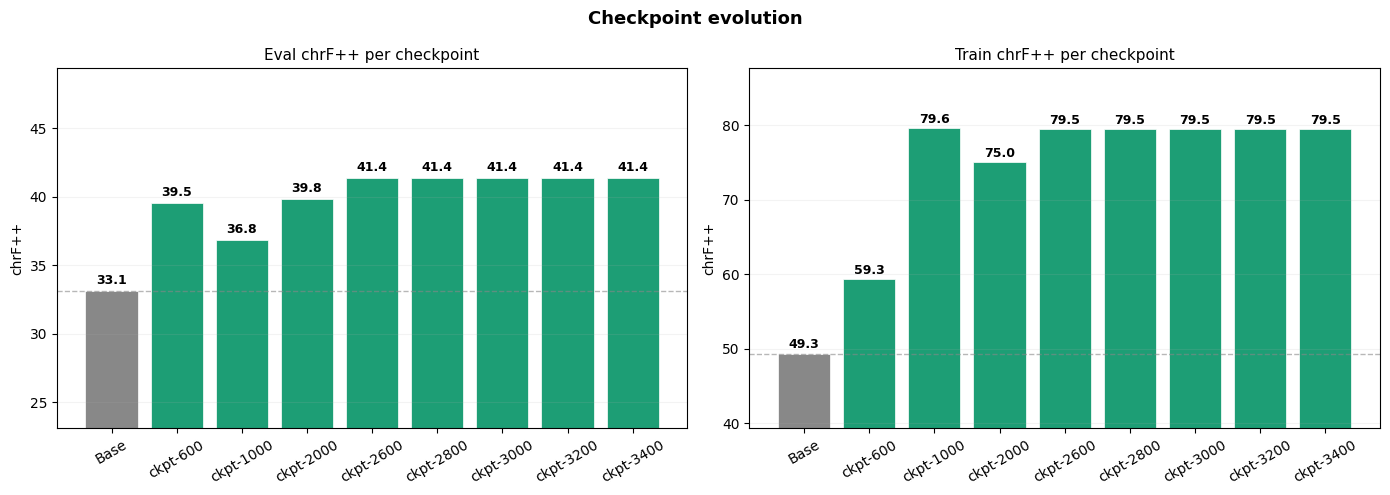

Saved → /content/drive/MyDrive/mathtrans/checkpoints/checkpoint_comparison.png


In [ ]:
# 7.3 Per-checkpoint chrF++ bar chart (requires Section 6.4 sweep)
if not sweep_results:
    print("Run Section 6.4 first.")
else:
    GREEN='#1D9E75'; ORANGE='#D85A30'
    names=['Base']+[r['name'].replace('checkpoint-','ckpt-') for r in sweep_results]
    fig,axes=plt.subplots(1,2,figsize=(14,5))
    fig.suptitle('Checkpoint evolution',fontsize=13,fontweight='bold')
    for ax,(key,ref,title) in zip(axes,[
        ('chrf_eval', base_chrf_e,'Eval chrF++ per checkpoint'),
        ('chrf_train',base_chrf_t,'Train chrF++ per checkpoint'),
    ]):
        vals=[ref]+[r[key] for r in sweep_results]
        colors_bar=['#888']+[GREEN if v>ref else ORANGE for v in vals[1:]]
        bars=ax.bar(names,vals,color=colors_bar,edgecolor='white',linewidth=0.5)
        ax.axhline(y=ref,color='#888',linestyle='--',linewidth=1,alpha=0.6)
        for bar,val in zip(bars,vals):
            ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+0.3,
                    f'{val:.1f}',ha='center',va='bottom',fontsize=9,fontweight='bold')
        ax.set_title(title,fontsize=11); ax.set_ylabel('chrF++')
        ax.set_ylim(max(0,ref-10),max(vals)+8)
        ax.tick_params(axis='x',rotation=30); ax.grid(axis='y',alpha=0.15)
    plt.tight_layout()
    out=f'{CKPT_DIR}/checkpoint_comparison.png'
    plt.savefig(out,dpi=150,bbox_inches='tight')
    plt.show()
    print(f"Saved → {out}")

## Section 8 — arXiv / PDF translator

**About the metrics question:** Plots belong in Section 7, not here. Mixing training diagnostics into the translation UI would clutter both workflows. The interface stays focused: input → clean output. That is the right practice.

In [ ]:
# 8.1 Load translation model (final or latest checkpoint)
from pathlib import Path as P
final_dir=P(CKPT_DIR)/'final'
if final_dir.exists():
    print(f"Loading final merged model from {final_dir}")
    trans_tok=NllbTokenizerFast.from_pretrained(str(final_dir))
    trans_mdl=AutoModelForSeq2SeqLM.from_pretrained(
        str(final_dir),torch_dtype=torch.float16 if device=='cuda' else torch.float32
    ).to(device)
else:
    ckpts=find_checkpoints(CKPT_DIR)
    if ckpts:
        from peft import PeftModel as PM
        latest=ckpts[-1]
        print(f"Final model not ready. Loading latest checkpoint: {latest.name}")
        trans_tok=NllbTokenizerFast.from_pretrained(str(latest))
        _b=AutoModelForSeq2SeqLM.from_pretrained(
            MODEL_NAME,torch_dtype=torch.float16 if device=='cuda' else torch.float32)
        _b.resize_token_embeddings(len(trans_tok))
        trans_mdl=PM.from_pretrained(_b,str(latest)).to(device)
    else:
        print("No fine-tuned model. Using base NLLB.")
        trans_tok=base_tok; trans_mdl=base_mdl
trans_mdl.eval()
print("Translation model ready.")

Loading final merged model from /content/drive/MyDrive/mathtrans/checkpoints/final


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


Translation model ready.


In [ ]:
# 8.2 Fetch & translation helpers
import requests
from bs4 import BeautifulSoup

def fetch_arxiv_abstract(arxiv_id):
    url=f'https://arxiv.org/abs/{arxiv_id}'
    r=requests.get(url,headers={'User-Agent':'MathTrans/1.0'},timeout=15)
    if r.status_code!=200: raise ValueError(f'arXiv {r.status_code} for {arxiv_id}')
    soup=BeautifulSoup(r.text,'html.parser')
    t=soup.find('h1',class_='title')
    a=soup.find('blockquote',class_='abstract')
    title=t.get_text(strip=True).replace('Title:','').strip() if t else '(no title)'
    abstract=a.get_text(strip=True).replace('Abstract:','').strip() if a else '(no abstract)'
    return title,abstract

def fetch_arxiv_html(arxiv_id,max_chars=6000):
    url=f'https://arxiv.org/html/{arxiv_id}'
    try:
        r=requests.get(url,headers={'User-Agent':'MathTrans/1.0'},timeout=20)
        if r.status_code!=200: return None,'HTML not available for this paper'
    except Exception as e: return None,str(e)
    soup=BeautifulSoup(r.text,'html.parser')
    paragraphs=[]
    for p in soup.find_all('p'):
        for math in p.find_all('math'):
            ann=math.find('annotation',{'encoding':'application/x-tex'})
            if ann: math.replace_with(f'${ann.get_text(strip=True)}$')
        text=p.get_text(' ',strip=True)
        if len(text)>30: paragraphs.append(text)
    return '\n\n'.join(paragraphs)[:max_chars],None

def pdf_to_text(pdf_path):
    try:
        import pymupdf4llm
        return pymupdf4llm.to_markdown(pdf_path)[:6000]
    except Exception as e: return f'PDF extraction failed: {e}'

def translate_block(text,src='en',tgt='ar',beams=4):
    sents=split_sentences(text)
    if not sents: return ''
    out=[]
    for s in sents:
        if len(s.strip())<5: out.append(s); continue
        out.append(translate(s,trans_tok,trans_mdl,src=src,tgt=tgt,beams=beams))
    return ' '.join(out)

def show_result(title,en_text,ar_text,extra_en=None,extra_ar=None):
    extra_html=''
    if extra_en and extra_ar:
        extra_html=f'''<div style="border-top:1px solid #eee">
          <div style="background:#f7f7f5;padding:8px 16px;font-size:11px;font-weight:600;
                      letter-spacing:.06em;color:#888;text-transform:uppercase">Full paper</div>
          <div style="display:grid;grid-template-columns:1fr 1fr">
            <div style="padding:12px 16px;border-right:1px solid #eee;max-height:360px;overflow-y:auto;
                        font-size:12px;line-height:1.7;color:#555;white-space:pre-wrap">{extra_en[:2500]}...</div>
            <div style="padding:12px 16px;max-height:360px;overflow-y:auto;
                        font-size:13px;line-height:1.8;direction:rtl;text-align:right;
                        color:#333;white-space:pre-wrap">{extra_ar[:2500]}...</div>
          </div></div>'''
    display(HTML(f'''<div style="font-family:sans-serif;max-width:920px;border:1px solid #ddd;
                                 border-radius:8px;overflow:hidden;margin:8px 0">
      <div style="background:#f7f7f5;padding:12px 16px;border-bottom:1px solid #ddd">
        <div style="font-size:11px;color:#888;margin-bottom:3px">Paper</div>
        <div style="font-size:15px;font-weight:500">{title}</div>
      </div>
      <div style="display:grid;grid-template-columns:1fr 1fr">
        <div style="padding:14px 16px;border-right:1px solid #eee">
          <div style="font-size:11px;font-weight:600;letter-spacing:.06em;color:#185FA5;
                      margin-bottom:8px;text-transform:uppercase">English</div>
          <div style="font-size:13px;line-height:1.7;color:#333">{en_text}</div>
        </div>
        <div style="padding:14px 16px">
          <div style="font-size:11px;font-weight:600;letter-spacing:.06em;color:#1D9E75;
                      margin-bottom:8px;text-transform:uppercase">Arabic translation</div>
          <div style="font-size:14px;line-height:1.9;direction:rtl;text-align:right;color:#333">{ar_text}</div>
        </div>
      </div>
      {extra_html}
    </div>'''))

print("Helpers ready.")

Helpers ready.


In [ ]:
# 8.3 Translate by arXiv ID
# ✏️  Paste any arXiv math paper ID here
ARXIV_ID = '2301.07685'
TRANSLATE_FULL = False   # set True to also translate intro/body

print(f"Fetching arXiv:{ARXIV_ID} ...")
title,abstract=fetch_arxiv_abstract(ARXIV_ID)
print(f"Title    : {title}")
print(f"Abstract : {abstract[:200]}...")

print("Translating abstract ...")
abstract_ar=translate_block(abstract)

extra_en=extra_ar=None
if TRANSLATE_FULL:
    print("Fetching full HTML paper ...")
    extra_en,err=fetch_arxiv_html(ARXIV_ID)
    if err: print(f"  Note: {err}")
    elif extra_en:
        print(f"Translating {len(extra_en)} chars ...")
        extra_ar=translate_block(extra_en)

show_result(title,abstract,abstract_ar,extra_en,extra_ar)

Fetching arXiv:2301.07685 ...
Title    : Factors other than climate change are currently more important in predicting how well fruit farms are doing financially
Abstract : Machine learning and statistical modeling methods were used to analyze the impact of climate change on financial wellbeing of fruit farmers in Tunisia and Chile. The analysis was based on face to face...
Translating abstract ...


In [ ]:
# 8.4 Translate uploaded PDF (Abstract Only)
from google.colab import files
import re

print("Upload a PDF (digitally-produced, not scanned):")
uploaded = files.upload()

if uploaded:
    fname = list(uploaded.keys())[0]
    print(f"\nExtracting text from {fname} ...")
    raw = pdf_to_text(fname)

    if raw.startswith('PDF extraction failed'):
        print(raw)
    else:
        # Regex to find Abstract and stop at Introduction
        # (?i) makes it case insensitive. \b ensures it matches whole words.
        regex_pattern = r'(?i)\babstract\b(.*?)(?:\bintroduction\b|\b1\.\s*introduction\b|\bi\.\s*introduction\b)'
        match = re.search(regex_pattern, raw, re.DOTALL)

        if match:
            abstract_text = match.group(1).strip()
            print(f"\n✅ Abstract automatically detected! ({len(abstract_text)} chars).")
            print(f"Preview: {abstract_text[:300]}...\n")

            print("Translating Abstract with high accuracy...")
            ar = translate_block(abstract_text)
            show_result(fname + " (Abstract)", abstract_text, ar)
        else:
            print("\n⚠️ Could not automatically detect an 'Abstract' section.")
            print("The PDF might use non-standard formatting. Here is the start of the file instead:")
            print(raw[:500])
else:
    print("No file uploaded.")

Upload a PDF (digitally-produced, not scanned):


Saving 2604.13514v1.pdf to 2604.13514v1.pdf

Extracting text from 2604.13514v1.pdf ...
=== Document parser messages ===
Using Tesseract for OCR processing.

Extracted 6000 chars. First 300:
# **Automated Tactics for Polynomial Reasoning in Lean 4** 

Hao Shen[1] , Junyu Guo[2] , Junqi Liu[1] , and Lihong Zhi[1] 

> 1 State Key Laboratory of Mathematical Sciences, Academy of Mathematics and Systems Science, University of Chinese Academy of Science, Beijing, 100190, China 

```
{shenhao2

Translating (first 4000 chars) ...


## Section 9 — Phase 2 Training: 11 k Cleaned Dataset

### Why a second training run?
After the first Phase 1 run we plotted loss, chrF++ and BLEU (Section 7).  
The curves showed **no meaningful improvement after checkpoint 2600** — the model had plateaued on the original `phase1.jsonl` data.

To test whether new, cleaned data can push past that ceiling we now run a **fresh LoRA fine-tune on `dataset_cleaned.jsonl`** (≈ 11 k pairs).  
The new data goes through the **entire pre-training pipeline** (dedup → sentence-split → tokenise → train from scratch with its own LoRA adapters).

### Hyperparameter changes vs Phase 1 and their justification

| Parameter | Phase 1 value | Phase 2 value | Rationale |
|---|---|---|---|
| `gradient_accumulation_steps` | 16 (eff. batch 64) | **8 (eff. batch 32)** | 11 k examples → ~half the data. Smaller effective batch gives the optimiser more gradient updates per epoch, helping the model generalise on limited data. |
| `learning_rate` | 3e-4 | **5e-4** | With fewer samples per epoch the loss landscape has higher curvature locally; a slightly higher LR helps escape flat regions early. Mitigated by the longer warmup below. |
| `warmup_ratio` | 0.06 | **0.10** | Counterbalances the higher LR: a longer warm-up (10 % of steps) avoids destructive early updates on a small dataset. |
| `num_train_epochs` | 3 | **5** | 11 k pairs produce fewer steps per epoch. More epochs compensate so the model sees enough gradient signal before early stopping kicks in. |
| `lora_dropout` | 0.05 | **0.10** | Stronger regularisation because the dataset is ~7× smaller; higher dropout reduces overfitting. |
| `val_split` | 0.05 (5 %) | **0.10 (10 %)** | A 5 % split of 11 k gives only ~550 validation examples — too noisy for reliable chrF++ estimates. 10 % gives ~1 100 examples, a more stable signal. |
| `eval_steps` / `save_steps` | 200 | **100** | Steps per epoch are shorter; evaluating every 100 steps gives finer granularity to catch the best checkpoint. |
| `save_total_limit` | 5 | **None** | Keep every checkpoint for the post-training sweep (Section 10). |

> **Starting point:** Phase 2 loads the **Phase 1 final merged model** (or falls back to base NLLB if it is not saved yet) and applies a fresh LoRA on top, so it benefits from the domain adaptation already learned in Phase 1.


### 9.0 — Paths & config for Phase 2

In [ ]:
# 9.0  Phase-2 paths and hyperparameters
# ─────────────────────────────────────────────────────────────────────────────
# All Phase-2 artefacts live under a separate sub-folder so they never
# overwrite the Phase-1 checkpoints or curves.
# ─────────────────────────────────────────────────────────────────────────────
import os, random
from pathlib import Path

DRIVE_ROOT_P2  = '/content/drive/MyDrive/mathtrans'          # same Drive root
DATA_PATH_P2   = f'{DRIVE_ROOT_P2}/dataset_cleaned.jsonl'    # 11 k cleaned pairs
CKPT_DIR_P2    = f'{DRIVE_ROOT_P2}/checkpoints_phase2'
FINAL_DIR_P2   = f'{DRIVE_ROOT_P2}/final_phase2'
CURVES_PATH_P2 = f'{CKPT_DIR_P2}/training_curves_phase2.json'

# Phase-1 final merged model used as warm-start (optional but recommended)
PHASE1_FINAL   = f'{DRIVE_ROOT_P2}/checkpoints/final'   # written by Section 5 merge_and_unload

os.makedirs(CKPT_DIR_P2,  exist_ok=True)
os.makedirs(FINAL_DIR_P2, exist_ok=True)

# ── Hyperparameters ─────────────────────────────────────────────────────────
# Changes vs Phase 1 are annotated inline; see the table in the section header.
LORA_CONFIG_P2 = dict(
    r=16, lora_alpha=32,
    target_modules=['q_proj','k_proj','v_proj','out_proj'],
    lora_dropout=0.10,          # ↑ 0.05 → 0.10  (stronger regularisation, small dataset)
    bias='none',
    task_type=TaskType.SEQ_2_SEQ_LM,
)

TRAIN_CONFIG_P2 = dict(
    max_source_length=256, max_target_length=256,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=8,   # ↓ 16 → 8   (more updates / epoch on small data)
    learning_rate=5e-4,              # ↑ 3e-4 → 5e-4 (higher LR, offset by longer warmup)
    lr_scheduler_type='cosine',
    warmup_ratio=0.10,               # ↑ 0.06 → 0.10 (longer warmup guards the higher LR)
    num_train_epochs=5,              # ↑ 3 → 5       (fewer steps/epoch, need more passes)
    weight_decay=0.01,
    label_smoothing_factor=0.0,
    val_split=0.10,                  # ↑ 0.05 → 0.10 (stable val signal with 11 k pairs)
    logging_steps=25,
    eval_steps=100,                  # ↓ 200 → 100   (finer checkpoint granularity)
    save_steps=100,
    save_total_limit=None,           # keep ALL checkpoints for Section 10 sweep
    eval_num_beams=1,
    eval_generation_max_length=128,
    final_num_beams=4,
    final_generation_max_length=256,
    seed=42,
)

random.seed(TRAIN_CONFIG_P2['seed'])
np.random.seed(TRAIN_CONFIG_P2['seed'])
torch.manual_seed(TRAIN_CONFIG_P2['seed'])

print("Phase-2 paths:")
print(f"  Data     : {DATA_PATH_P2}  (exists: {os.path.exists(DATA_PATH_P2)})")
print(f"  Ckpt dir : {CKPT_DIR_P2}")
print(f"  Final dir: {FINAL_DIR_P2}")
print(f"  Warm-start: {PHASE1_FINAL}  (exists: {os.path.exists(PHASE1_FINAL)})")
print("\nPhase-2 hyperparameters:")
for k,v in TRAIN_CONFIG_P2.items():
    print(f"  {k:<35} = {v}")


In [ ]:
# 9.1  Load and inspect Phase-2 dataset  (full pipeline — no shortcuts)
# ─────────────────────────────────────────────────────────────────────────────
# The 11 k cleaned dataset goes through the exact same dedup + sentence-split
# pipeline as Phase 1 (Section 2.3).  We pass retrain_all=True because none of
# these hashes were seen in Phase 1 (different source file).
# ─────────────────────────────────────────────────────────────────────────────
SEEN_PATH_P2 = f'{DRIVE_ROOT_P2}/seen_hashes_phase2.txt'

seen_p2 = load_seen_hashes(SEEN_PATH_P2)
print(f"Pre-existing seen hashes for Phase 2: {len(seen_p2)}")

datasets_p2, new_hashes_p2 = load_data(
    [DATA_PATH_P2],
    seen_hashes=seen_p2,
    val_split=TRAIN_CONFIG_P2['val_split'],
    seed=TRAIN_CONFIG_P2['seed'],
    retrain_all=False,       # skip already-seen pairs from previous P2 runs
)
print(f"\nPhase-2 split:")
# # Direction balance check
# en2ar = sum(1 for r in datasets_p2['train'] if r['source'].startswith('<en2ar>'))
# ar2en = len(datasets_p2['train']) - en2ar
# print(f"  EN→AR : {en2ar}  ({100*en2ar/(en2ar+ar2en):.0f}%)")
# print(f"  AR→EN : {ar2en}  ({100*ar2en/(en2ar+ar2en):.0f}%)")
# ── inspection ──
if os.path.exists(DATA_PATH_P2):
    seen=load_seen_hashes(SEEN_PATH_P2)
    print(f"Seen hashes: {len(seen)}")
    datasets,new_hashes=load_data([DATA_PATH],seen)
    src_lens=[len(r['source'].split()) for r in datasets['train']]
    tgt_lens=[len(r['target'].split()) for r in datasets['train']]
    en2ar=sum(1 for r in datasets['train'] if r['source'].startswith('<en2ar>'))
    ar2en=len(datasets['train'])-en2ar
    print(f"  Train/Val split : {len(datasets['train'])} / {len(datasets['validation'])}")
    print(f"  EN→AR / AR→EN   : {en2ar} / {ar2en}  ({100*en2ar/(en2ar+ar2en):.0f}% / {100*ar2en/(en2ar+ar2en):.0f}%)")
    print(f"  Src words avg/p95: {np.mean(src_lens):.1f} / {np.percentile(src_lens,95):.0f}")
    print(f"  Tgt words avg/p95: {np.mean(tgt_lens):.1f} / {np.percentile(tgt_lens,95):.0f}")
else:
    print(f"Data not found at {DATA_PATH} — upload your JSONL first")

In [ ]:
# 9.2  Tokenise Phase-2 dataset
# ─────────────────────────────────────────────────────────────────────────────
# Reuses make_tokenize_fn from Section 2.4; tokenizer already loaded in S3.
# ─────────────────────────────────────────────────────────────────────────────
tokenize_fn_p2 = make_tokenize_fn(
    tokenizer,
    TRAIN_CONFIG_P2['max_source_length'],
    TRAIN_CONFIG_P2['max_target_length'],
)

tokenized_p2 = datasets_p2.map(
    tokenize_fn_p2,
    batched=True,
    remove_columns=['source','target'],
    desc='Tokenising Phase-2 data',
)

# src_lens = [len(x) for x in tokenized_p2['train']['input_ids']]
# tgt_lens = [len(x) for x in tokenized_p2['train']['labels'] if x]
# print(f"Train tokens — src avg/p95: {np.mean(src_lens):.1f} / {np.percentile(src_lens,95):.0f}")
# print(f"Labels       — tgt avg/p95: {np.mean(tgt_lens):.1f} / {np.percentile(tgt_lens,95):.0f}")
# print(f"Tokenised train: {len(tokenized_p2['train'])}  val: {len(tokenized_p2['validation'])}")
row=tokenized['train'][0]
print(f"\nTokenised row shape:")
print(f"  input_ids      : ({len(row['input_ids'])},)")
print(f"  attention_mask : ({len(row['attention_mask'])},)")
print(f"  labels         : ({len(row['labels'])},)   first 10: {row['labels'][:10]}")
print(f"  (-100 = padding token, ignored in loss)")
tok_lens=[len(r['input_ids']) for r in tokenized['train']]
trunc=sum(1 for l in tok_lens if l==TRAIN_CONFIG['max_source_length'])
print(f"\nToken length distribution:")
print(f"  avg={np.mean(tok_lens):.1f}  p95={np.percentile(tok_lens,95):.0f}  max={max(tok_lens)}")
print(f"  Truncated at 256: {trunc} ({100*trunc/len(tok_lens):.1f}%)  — ideally <2%")


In [ ]:
# 9.3  Load warm-start model and apply fresh LoRA for Phase 2
# ─────────────────────────────────────────────────────────────────────────────
# Preferred: start from the Phase-1 final merged model so Phase 2 inherits
# the domain adaptation already achieved.
# Fallback: base NLLB-200-1.3B (same as Phase-1 start).
# ─────────────────────────────────────────────────────────────────────────────
from peft import LoraConfig as LC2, get_peft_model as gpm2

if os.path.exists(PHASE1_FINAL) and os.path.isdir(PHASE1_FINAL):
    print(f"Warm-starting Phase 2 from Phase-1 final: {PHASE1_FINAL}")
    base_for_p2 = AutoModelForSeq2SeqLM.from_pretrained(
        PHASE1_FINAL,
        torch_dtype=torch.float16 if device=='cuda' else torch.float32,
    )
else:
    print(f"Phase-1 final not found at {PHASE1_FINAL}")
    print(f"Falling back to base NLLB: {MODEL_NAME}")
    base_for_p2 = AutoModelForSeq2SeqLM.from_pretrained(
        MODEL_NAME,
        torch_dtype=torch.float16 if device=='cuda' else torch.float32,
    )

base_for_p2.resize_token_embeddings(len(tokenizer))
lora_cfg_p2 = LC2(**LORA_CONFIG_P2)
model_p2 = gpm2(base_for_p2, lora_cfg_p2)
model_p2.print_trainable_parameters()
print(f"Phase-2 model on device: {device}")


In [ ]:
# 9.4  Train Phase 2  — auto-resumes from latest checkpoint
# ─────────────────────────────────────────────────────────────────────────────
# All callbacks and the trainer structure mirror Section 5 exactly.
# save_total_limit=None → every checkpoint is kept for the Section 10 sweep.
# ─────────────────────────────────────────────────────────────────────────────
cfg2 = TRAIN_CONFIG_P2

training_args_p2 = Seq2SeqTrainingArguments(
    output_dir=CKPT_DIR_P2,
    per_device_train_batch_size=cfg2['per_device_train_batch_size'],
    per_device_eval_batch_size=cfg2['per_device_eval_batch_size'],
    gradient_accumulation_steps=cfg2['gradient_accumulation_steps'],
    learning_rate=cfg2['learning_rate'],
    lr_scheduler_type=cfg2['lr_scheduler_type'],
    warmup_ratio=cfg2['warmup_ratio'],
    num_train_epochs=cfg2['num_train_epochs'],
    weight_decay=cfg2['weight_decay'],
    label_smoothing_factor=cfg2['label_smoothing_factor'],
    fp16=(device=='cuda'),
    save_strategy='steps',
    save_steps=cfg2['save_steps'],
    save_total_limit=cfg2['save_total_limit'],
    evaluation_strategy='steps',
    eval_steps=cfg2['eval_steps'],
    predict_with_generate=True,
    generation_num_beams=cfg2['eval_num_beams'],
    generation_max_length=cfg2['eval_generation_max_length'],
    logging_steps=cfg2['logging_steps'],
    report_to='none',
    seed=cfg2['seed'],
    load_best_model_at_end=True,
    metric_for_best_model='eval_chrf',
    greater_is_better=True,
)

compute_metrics_p2 = build_compute_metrics(tokenizer)

trainer_p2 = Seq2SeqTrainer(
    model=model_p2,
    args=training_args_p2,
    train_dataset=tokenized_p2['train'],
    eval_dataset=tokenized_p2['validation'],
    tokenizer=tokenizer,
    data_collator=DataCollatorForSeq2Seq(
        tokenizer, model=model_p2, padding='longest', label_pad_token_id=-100
    ),
    compute_metrics=compute_metrics_p2,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=3),  # patience=3 for longer run
        ClearCacheBeforeEval(),
        SaveCurvesCallback(CURVES_PATH_P2),
    ],
)

# Auto-resume from latest Phase-2 checkpoint if Colab disconnected
p2_ckpts = find_checkpoints(CKPT_DIR_P2)
resume_from = str(p2_ckpts[-1]) if p2_ckpts else None
if resume_from:
    print(f"Resuming Phase-2 training from: {resume_from}")
else:
    print("Starting Phase-2 training from scratch.")

trainer_p2.train(resume_from_checkpoint=resume_from)

# Merge and save
print("\nMerging LoRA adapters into base model …")
merged_p2 = trainer_p2.model.merge_and_unload()
merged_p2.save_pretrained(FINAL_DIR_P2)
tokenizer.save_pretrained(FINAL_DIR_P2)

# Persist new hashes so re-runs skip already-seen pairs
save_new_hashes(SEEN_PATH_P2, new_hashes_p2)

print(f"\n✓ Phase-2 final model saved → {FINAL_DIR_P2}")
print(f"  Phase-2 checkpoints: {len(find_checkpoints(CKPT_DIR_P2))}")


## Section 10 — Phase 2 Checkpoint Explorer & Metrics

Run after Section 9 completes.  
Mirrors Sections 6–7 exactly, but pointed at the Phase-2 checkpoints and curves.  
The side-by-side bar charts at the end let you directly compare Phase 1 and Phase 2 evolution.


In [ ]:
# 10.1  Sweep all Phase-2 checkpoints  (100 train + 100 val examples each)
# Reuses score_100 / evaluate_100_samples from Section 6 — those functions
# are already defined in this session.  We just point them at Phase-2 data.

from peft import PeftModel as PM2

def sweep_p2_checkpoints(ckpt_dir, base_ref, dataset_dict_p2):
    ckpts = find_checkpoints(ckpt_dir)
    if not ckpts:
        print("No Phase-2 checkpoints found. Run Section 9 first.")
        return []
    results = []
    # sample once for reproducibility
    rng = np.random.default_rng(TRAIN_CONFIG_P2['seed'])
    n_train = min(100, len(dataset_dict_p2['train']))
    n_val   = min(100, len(dataset_dict_p2['validation']))
    idx_tr  = rng.choice(len(dataset_dict_p2['train']),  n_train, replace=False)
    idx_val = rng.choice(len(dataset_dict_p2['validation']), n_val, replace=False)
    train_sample = dataset_dict_p2['train'].select(idx_tr)
    val_sample   = dataset_dict_p2['validation'].select(idx_val)

    chrf_m = hf_evaluate.load('chrf')
    bleu_m = hf_evaluate.load('sacrebleu')

    def score_samples(mdl, tok, samples):
        preds, refs = [], []
        for row in samples:
            src = row['source']
            if src.startswith('<en2ar>'):
                tok.src_lang = LANG_CODE['en']; tgt_lang = LANG_CODE['ar']
                clean = src[7:].strip()
            elif src.startswith('<ar2en>'):
                tok.src_lang = LANG_CODE['ar']; tgt_lang = LANG_CODE['en']
                clean = src[7:].strip()
            else:
                has_ar = any('\u0600' <= c <= '\u06FF' for c in src)
                tok.src_lang = LANG_CODE['ar' if has_ar else 'en']
                tgt_lang     = LANG_CODE['en' if has_ar else 'ar']
                clean = src
            enc = tok(clean, return_tensors='pt', max_length=256, truncation=True).to(device)
            with torch.no_grad():
                out = mdl.generate(
                    **enc,
                    max_length=TRAIN_CONFIG_P2['eval_generation_max_length'],
                    num_beams=TRAIN_CONFIG_P2['eval_num_beams'],
                    forced_bos_token_id=tok.lang_code_to_id[tgt_lang],
                )
            preds.append(tok.decode(out[0], skip_special_tokens=True).strip())
            refs.append(row['target'].strip())
        c = chrf_m.compute(predictions=preds, references=refs, word_order=2)['score']
        b = bleu_m.compute(predictions=preds, references=[[r] for r in refs])['score']
        return round(c, 2), round(b, 2)

    base_model_p2 = AutoModelForSeq2SeqLM.from_pretrained(
        base_ref,
        torch_dtype=torch.float16 if device=='cuda' else torch.float32,
    )
    base_model_p2.resize_token_embeddings(len(tokenizer))

    for ckpt in ckpts:
        name = ckpt.name
        print(f"  Scoring {name} …", end=' ', flush=True)
        ft = PM2.from_pretrained(base_model_p2, str(ckpt)).merge_and_unload().to(device)
        ft.eval()
        ct, bt = score_samples(ft, tokenizer, train_sample)
        cv, bv = score_samples(ft, tokenizer, val_sample)
        print(f"train chrF++={ct}  val chrF++={cv}")
        results.append({'name': name, 'chrf_train': ct, 'bleu_train': bt,
                        'chrf_eval': cv, 'bleu_eval': bv})
        del ft; torch.cuda.empty_cache()

    del base_model_p2; torch.cuda.empty_cache()
    return results

# Determine which base to use for Phase-2 adapter loading
p2_base_ref = PHASE1_FINAL if os.path.exists(PHASE1_FINAL) else MODEL_NAME
sweep_results_p2 = sweep_p2_checkpoints(CKPT_DIR_P2, p2_base_ref, datasets_p2)
print(f"\n✓ Swept {len(sweep_results_p2)} Phase-2 checkpoints.")


In [ ]:
# 10.2  Phase-2 training curves — loss, chrF++, BLEU, learning rate
import math as _math

if not os.path.exists(CURVES_PATH_P2):
    print(f"No curves at {CURVES_PATH_P2} — train first (Section 9).")
else:
    with open(CURVES_PATH_P2) as f:
        history_p2 = json.load(f)
    print(f"Loaded {len(history_p2)} log entries.")

    train_logs = [h for h in history_p2 if 'loss' in h and 'eval_loss' not in h]
    eval_logs  = [h for h in history_p2 if 'eval_chrf' in h]

    st = [h['step'] for h in train_logs]
    lt = [h['loss'] for h in train_logs]
    lr = [h.get('learning_rate', 0) for h in train_logs]
    se = [h['step']      for h in eval_logs]
    ce = [h['eval_chrf'] for h in eval_logs]
    be = [h['eval_bleu'] for h in eval_logs]
    el = [h.get('eval_loss') for h in eval_logs]

    cfg2 = TRAIN_CONFIG_P2
    spe = _math.ceil(
        len(tokenized_p2['train']) /
        (cfg2['per_device_train_batch_size'] * cfg2['gradient_accumulation_steps'])
    )
    epoch_marks = [spe * (i + 1) for i in range(cfg2['num_train_epochs'])]

    BLUE = '#185FA5'; GREEN = '#1D9E75'; ORANGE = '#D85A30'; PURPLE = '#534AB7'; TARGET = '#BA7517'

    def epoch_lines_p2(ax):
        ylim = ax.get_ylim()
        for es in epoch_marks:
            ax.axvline(x=es, color='#aaa', linestyle=':', linewidth=0.8, alpha=0.7)
            ax.text(es + max(st + [1]) / 150, ylim[0] + (ylim[1] - ylim[0]) * 0.03,
                    'ep', fontsize=8, color='#aaa')

    import matplotlib.ticker as ticker2
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle('MathTrans Phase 2 (11 k cleaned) — Training metrics',
                 fontsize=14, fontweight='bold')

    # Loss
    ax = axes[0][0]
    if st: ax.plot(st, lt, color=BLUE, linewidth=1.5, label='train loss')
    valid_el = [(s, l) for s, l in zip(se, el) if l is not None]
    if valid_el:
        ax.plot([x[0] for x in valid_el], [x[1] for x in valid_el],
                'o--', color=ORANGE, markersize=4, linewidth=1, label='eval loss')
    epoch_lines_p2(ax)
    ax.set_title('Loss'); ax.set_xlabel('Step'); ax.set_ylabel('Cross-entropy')
    ax.legend(fontsize=9); ax.grid(alpha=0.15)
    ax.yaxis.set_major_formatter(ticker2.FormatStrFormatter('%.2f'))

    # chrF++
    ax = axes[0][1]
    if se:
        ax.plot(se, ce, color=GREEN, linewidth=2, marker='o', markersize=4, label='val chrF++')
        ax.axhline(y=45, color=TARGET, linestyle='--', linewidth=1.2, label='target 45', alpha=0.8)
        if ce:
            bi = ce.index(max(ce))
            ax.scatter([se[bi]], [ce[bi]], color=GREEN, s=80, zorder=5,
                       label=f'best={max(ce):.1f} @{se[bi]}')
    epoch_lines_p2(ax)
    ax.set_title('Validation chrF++ (primary)'); ax.set_xlabel('Step'); ax.set_ylabel('chrF++')
    ax.legend(fontsize=9); ax.grid(alpha=0.15)

    # BLEU
    ax = axes[1][0]
    if se:
        ax.plot(se, be, color=ORANGE, linewidth=2, marker='o', markersize=4, label='val BLEU')
        ax.axhline(y=25, color=TARGET, linestyle='--', linewidth=1.2, label='target 25', alpha=0.8)
    epoch_lines_p2(ax)
    ax.set_title('Validation BLEU (secondary)'); ax.set_xlabel('Step'); ax.set_ylabel('BLEU')
    ax.legend(fontsize=9); ax.grid(alpha=0.15)

    # LR
    ax = axes[1][1]
    if st: ax.plot(st, lr, color=PURPLE, linewidth=1.5, label='LR')
    epoch_lines_p2(ax)
    ax.set_title('Learning rate (cosine warmup)'); ax.set_xlabel('Step')
    ax.yaxis.set_major_formatter(ticker2.FormatStrFormatter('%.2e'))
    ax.legend(fontsize=9); ax.grid(alpha=0.15)

    plt.tight_layout()
    out = f'{CKPT_DIR_P2}/training_curves_phase2.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {out}")


In [ ]:
# 10.3  Phase-2 checkpoint bar chart (chrF++ & BLEU)
if not sweep_results_p2:
    print("Run Section 10.1 first.")
else:
    names_p2  = [r['name'].replace('checkpoint-', 'ckpt-') for r in sweep_results_p2]
    chrf_p2   = [r['chrf_eval']  for r in sweep_results_p2]
    bleu_p2   = [r['bleu_eval']  for r in sweep_results_p2]
    chrf_tr_p2= [r['chrf_train'] for r in sweep_results_p2]

    x = np.arange(len(names_p2))
    width = 0.35

    fig, ax = plt.subplots(figsize=(max(10, len(names_p2)*1.2), 6), facecolor='#f8f9fa')
    ax.bar(x - width/2, chrf_p2, width, label='val chrF++', color='#28a745', edgecolor='black')
    ax.bar(x + width/2, bleu_p2, width, label='val BLEU',   color='#007bff', edgecolor='black')

    for vals, offset in [(chrf_p2, -width/2), (bleu_p2, width/2)]:
        for xi, v in zip(x, vals):
            ax.annotate(f'{v:.1f}', xy=(xi + offset, v),
                        xytext=(0, 3), textcoords='offset points',
                        ha='center', va='bottom', fontsize=8)

    ax.set_ylabel('Score (0–100)', fontsize=11, fontweight='bold')
    ax.set_title('Phase 2 — Checkpoint evolution (val set)', fontsize=13, fontweight='bold')
    ax.set_xticks(x); ax.set_xticklabels(names_p2, rotation=45, ha='right', fontsize=9)
    ax.legend(fontsize=11); ax.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    out = f'{CKPT_DIR_P2}/phase2_checkpoint_bars.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {out}")


In [ ]:
# 10.4  Phase 1 vs Phase 2 — side-by-side comparison
# ─────────────────────────────────────────────────────────────────────────────
# Requires:  sweep_results (Phase 1, from Section 6.4)
#            sweep_results_p2 (Phase 2, from Section 10.1)
# ─────────────────────────────────────────────────────────────────────────────
import matplotlib.patches as mpatches

if not sweep_results or not sweep_results_p2:
    print("Run Section 6.4 (Phase 1 sweep) and Section 10.1 (Phase 2 sweep) first.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle('Phase 1 vs Phase 2 — Best checkpoint per run', fontsize=13, fontweight='bold')

    for ax, key, title in zip(
        axes,
        [('chrf_eval', 'eval_chrf'), ('bleu_eval', 'eval_bleu')],
        ['val chrF++', 'val BLEU'],
    ):
        k1, k2 = key

        # Phase 1: key is 'chrf' from Section 6.4 structure
        p1_vals = [r.get(k1, r.get('chrf', r.get('bleu', 0))) for r in sweep_results]
        p2_vals = [r[k1] for r in sweep_results_p2]

        best_p1 = max(p1_vals) if p1_vals else 0
        best_p2 = max(p2_vals) if p2_vals else 0

        cats   = ['Phase 1\n(plateau @ckpt-2600)', 'Phase 2\n(11 k cleaned)']
        vals   = [best_p1, best_p2]
        colors = ['#185FA5', '#1D9E75']

        bars = ax.bar(cats, vals, color=colors, edgecolor='black', width=0.5)
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.4,
                    f'{v:.1f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

        delta = best_p2 - best_p1
        sign  = '+' if delta >= 0 else ''
        ax.set_title(f'{title}  (Δ = {sign}{delta:.1f})', fontsize=11)
        ax.set_ylabel(title); ax.set_ylim(0, max(vals) + 8)
        ax.grid(axis='y', alpha=0.2)

    plt.tight_layout()
    out = f'{CKPT_DIR_P2}/phase1_vs_phase2.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {out}")
    if best_p2 > best_p1:
        print(f"\n✅ Phase 2 IMPROVED over Phase 1 by {best_p2 - best_p1:.1f} chrF++ points.")
    else:
        print(f"\n⚠️  Phase 2 did not surpass Phase 1 ({best_p2:.1f} vs {best_p1:.1f} chrF++).")
        print("   Consider: more data, higher LR warm-up, or longer training.")
